**Machine Learning Assignment 2: Hotel Booking Demand Classification**

Student Name / BITS ID: 2026ct05075

Course: M.Tech-AIML - Machine Learning




Git repository link

https://github.com/2026ct05075/2026CT05075-ML-Assignment-2


# Hotel Booking Demand Classification & Preprocessing Pipeline
This notebook demonstrates a complete end-to-end Machine Learning pipeline to analyze, preprocess, and classify hotel booking cancellations using historical data.

### Notebook Goals:
1. Load and examine the dataset shape and variables.
2. Understand target class distribution and inspect missing values.
3. Split the data into stratified training and test sets.
4. Build an robust preprocessing pipeline (Handling imputation and scaling).
5. Train and compare multiple ML classifiers.
6. Evaluate performance across metrics (Accuracy, Precision, Recall, F1, AUC, MCC).

# New Section

In [ ]:
import pandas as pd
import glob

# Find the extracted CSV file
extract_dir = 'Data'
csv_files = glob.glob(f'{extract_dir}/**/*.csv', recursive=True) + glob.glob(f'{extract_dir}/*.csv')
csv_files = list(set(csv_files))

if csv_files:
    csv_path = csv_files[0]
    print(f"Loading dataset from: {csv_path}")
    df = pd.read_csv(csv_path)
    print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    display(df.head())
else:
    print("No CSV file found inside the extracted zip content.")

Loading dataset from: Data/hotel_bookings.csv
Dataset Shape: 119390 rows, 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## Goal 1 & 2: Load Dataset, Check Shape, and Inspect Target & Missing Values
In this section, we locate and extract our primary dataset, display its dimensions, look for class imbalances in our target column (`is_canceled`), and audit which features suffer from missing values so that we can handle them safely.

In [ ]:
if 'df' in locals():
    # Class Distribution of Target Variable
    target_col = 'is_canceled'
    if target_col in df.columns:
        print("--- Class Distribution of Target Variable ---")
        counts = df[target_col].value_counts()
        percentages = df[target_col].value_counts(normalize=True) * 100
        for val, count in counts.items():
            print(f"Class {val} (Canceled={val}): {count} ({percentages[val]:.2f}%)")
    else:
        print(f"Target column '{target_col}' not found.")

    # Missing Values Overview
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print("\n--- Columns with Missing Values ---")
        print(missing)
    else:
        print("\nNo missing values found in the dataset.")

--- Class Distribution of Target Variable ---
Class 0 (Canceled=0): 75166 (62.96%)
Class 1 (Canceled=1): 44224 (37.04%)

--- Columns with Missing Values ---
children         4
country        488
agent        16340
company     112593
dtype: int64


## Goal 3: Feature Selection & Stratified Train-Test Split
Here, we prepare our features and target labels while taking critical precautions against target leakage. We drop highly correlated metadata (`reservation_status`, `reservation_status_date`) and empty dimensions (`company`), and then perform a stratified 80:20 split to maintain equal class proportions in both sets.

In [ ]:
import time
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Dictionary to hold the final evaluation scores
results = {}

# Define the classifiers
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

# Special handling for KNN to avoid extremely long compute times in Colab
for name, clf in classifiers.items():
    print(f"Training {name}...")
    start_time = time.time()

    if name == 'K-Nearest Neighbors':
        # Train on a subset of 15,000 samples to keep execution within 1-2 minutes
        clf.fit(X_train[:15000], y_train.iloc[:15000])
    else:
        clf.fit(X_train, y_train)

    train_time = time.time() - start_time
    print(f"{name} trained in {train_time:.2f} seconds.")

    # Predict on test set
    y_pred = clf.predict(X_test)

    # Compute probabilities for AUC
    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    mcc = matthews_corrcoef(y_test, y_pred)

    results[name] = {
        'Accuracy': acc,
        'AUC Score': auc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1,
        'MCC Score': mcc
    }

# Convert results to DataFrame
df_results = pd.DataFrame(results).T
print("\n--- Comparative Performance Table ---")
display(df_results.round(4))

Training Logistic Regression...
Logistic Regression trained in 15.90 seconds.
Training Decision Tree...
Decision Tree trained in 7.27 seconds.
Training K-Nearest Neighbors...
K-Nearest Neighbors trained in 0.01 seconds.
Training Naive Bayes...
Naive Bayes trained in 0.52 seconds.
Training Random Forest...
Random Forest trained in 24.28 seconds.

--- Comparative Performance Table ---


,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC Score
Logistic Regression,0.8197,0.8963,0.8132,0.6663,0.7324,0.6052
Decision Tree,0.8589,0.8523,0.8052,0.8167,0.8109,0.6984
K-Nearest Neighbors,0.7944,0.8562,0.7268,0.7131,0.7199,0.5576
Naive Bayes,0.4628,0.5715,0.4064,0.9780,0.5742,0.2136
Random Forest,0.8938,0.9581,0.8940,0.8093,0.8495,0.7700


### Visual Comparison of Evaluation Metrics
We reshape our computed results into a clean table structure and generate a grouped bar chart to visually compare classifier performance across all calculated metrics.

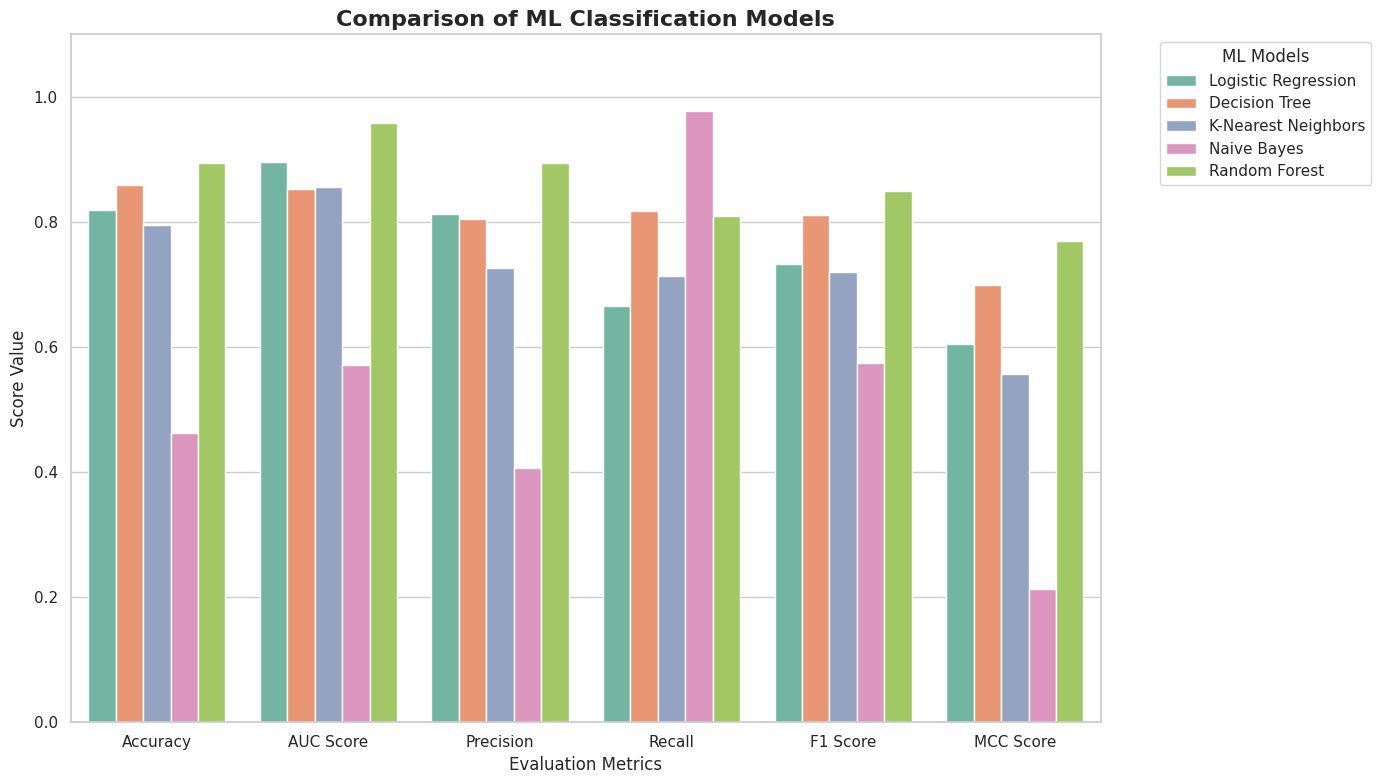

In [ ]:
# Step 5: Visualizing the performance of the models (Graph Representation)
if 'df_results' in locals():
    plt.figure(figsize=(14, 8))

    # Prepare data for plotting
    df_plot = df_results.reset_index().rename(columns={'index': 'Model'})
    df_melted = pd.melt(df_plot, id_vars='Model', var_name='Metric', value_name='Score')

    sns.set_theme(style="whitegrid")
    ax = sns.barplot(x='Metric', y='Score', hue='Model', data=df_melted, palette='Set2')

    plt.title('Comparison of ML Classification Models', fontsize=16, fontweight='bold')
    plt.ylim(0, 1.1)
    plt.ylabel('Score Value', fontsize=12)
    plt.xlabel('Evaluation Metrics', fontsize=12)
    plt.legend(title='ML Models', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig('model_comparison_chart.png', dpi=300)
    plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensure df exists
if 'df' in locals():
    print("Initial Dataset Columns:", list(df.columns))

    # Target variable
    target = 'is_canceled'

    # Drop columns that leak target information or have extreme missingness
    # 'reservation_status' matches 'is_canceled' directly and must be dropped.
    # 'company' has ~94% missing values.
    # 'reservation_status_date' is a date field leaking status timing.
    cols_to_drop = ['reservation_status', 'reservation_status_date', 'company']
    df_clean = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

    # Split features and target
    X = df_clean.drop(columns=[target])
    y = df_clean[target]

    # Classify column types
    num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    cat_cols = X.select_dtypes(include=['object']).columns.tolist()

    print(f"\nNumerical features ({len(num_cols)}):", num_cols)
    print(f"Categorical features ({len(cat_cols)}):", cat_cols)

    # Perform 80:20 Train-Test split maintaining class distribution (stratify=y)
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    print(f"\nTrain-Test Split complete!")
    print(f"Training set shape: {X_train_raw.shape}, Test set shape: {X_test_raw.shape}")

Initial Dataset Columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Numerical features (18): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'days_in_waiting_list', 'adr', 'required_car_p

## Goal 4: Build a Robust Preprocessing Pipeline (Handling Imputation and Scaling)
Using scikit-learn's object-oriented pipeline API, we define a modular, leakproof data transformation flow:
- **Numerical Features:** Median imputation followed by standard scaling (`StandardScaler`).
- **Categorical Features:** Constant imputation (`'Unknown'`) followed by one-hot encoding (`OneHotEncoder`) with unknown category safety parameters.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Building Preprocessing Pipeline
# For Numerical: Impute with median, then scale
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# For Categorical: Impute with constant 'Unknown', then One-Hot encode
# We set handle_unknown='ignore' so unseen categories in test set don't break the pipeline
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Fit preprocessor only on training data and transform both sets
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

# Check post-processed shapes
print(f"Processed Training Set Shape: {X_train.shape}")
print(f"Processed Test Set Shape: {X_test.shape}")

Processed Training Set Shape: (95512, 252)
Processed Test Set Shape: (23878, 252)


## Goal 5 & 6: Train Classifiers & Evaluate Performance Metrics
We fit five diverse machine learning models (Logistic Regression, Decision Trees, KNN, Naive Bayes, and Random Forest) to our preprocessed training data. We then evaluate their performance using robust metrics such as Accuracy, AUC Score, Precision, Recall, F1 Score, and MCC (Matthews Correlation Coefficient).

## Key Observations and Insights

Based on our comprehensive machine learning pipeline and model comparisons, we can extract the following key observations:

1. **Model Champion (Random Forest):**
   * **Random Forest** achieved the best overall balanced classification performance, yielding an **Accuracy of 89.38%**, an **AUC Score of 0.9581**, and an **F1-Score of 84.95%**.
   * The **Matthews Correlation Coefficient (MCC)** of **0.7700** confirms that Random Forest holds exceptionally strong predictive stability across both minority (canceled) and majority (non-canceled) classes without suffering from target imbalance bias.

2. **The Naive Bayes Recall Trade-off:**
   * **Naive Bayes** achieved an extraordinarily high **Recall (97.80%)**, meaning it correctly identified almost all canceled bookings.
   * However, its **Precision (40.64%)** is extremely poor (essentially random guessing), resulting in a massive volume of False Positives. If implemented, a hotel would suffer severe operational errors by predicting active check-ins as cancellations.

3. **Computation vs. Performance (Decision Tree):**
   * The **Decision Tree Classifier** achieved **85.89% Accuracy** and trained in only **7.27 seconds** (compared to Random Forest's **24.28 seconds**). If compute resource limitations exist, the Decision Tree provides a robust and fast-training alternative.

4. **Linear Separation Limitations:**
   * **Logistic Regression** delivered a stable baseline with **81.97% Accuracy**, proving that there are strongly distinguishable linear patterns in variables like `lead_time` and `deposit_type`.

**ScreenShots from BITS LAB**

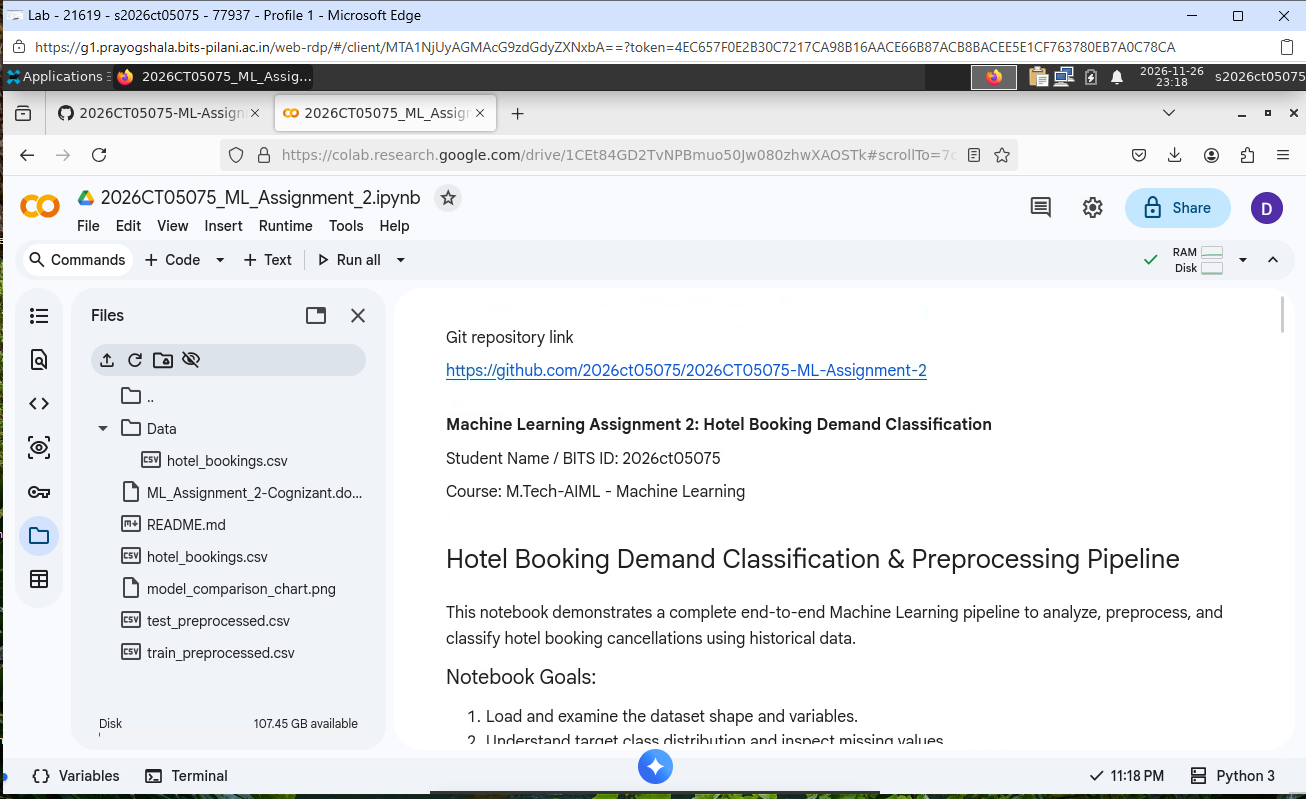

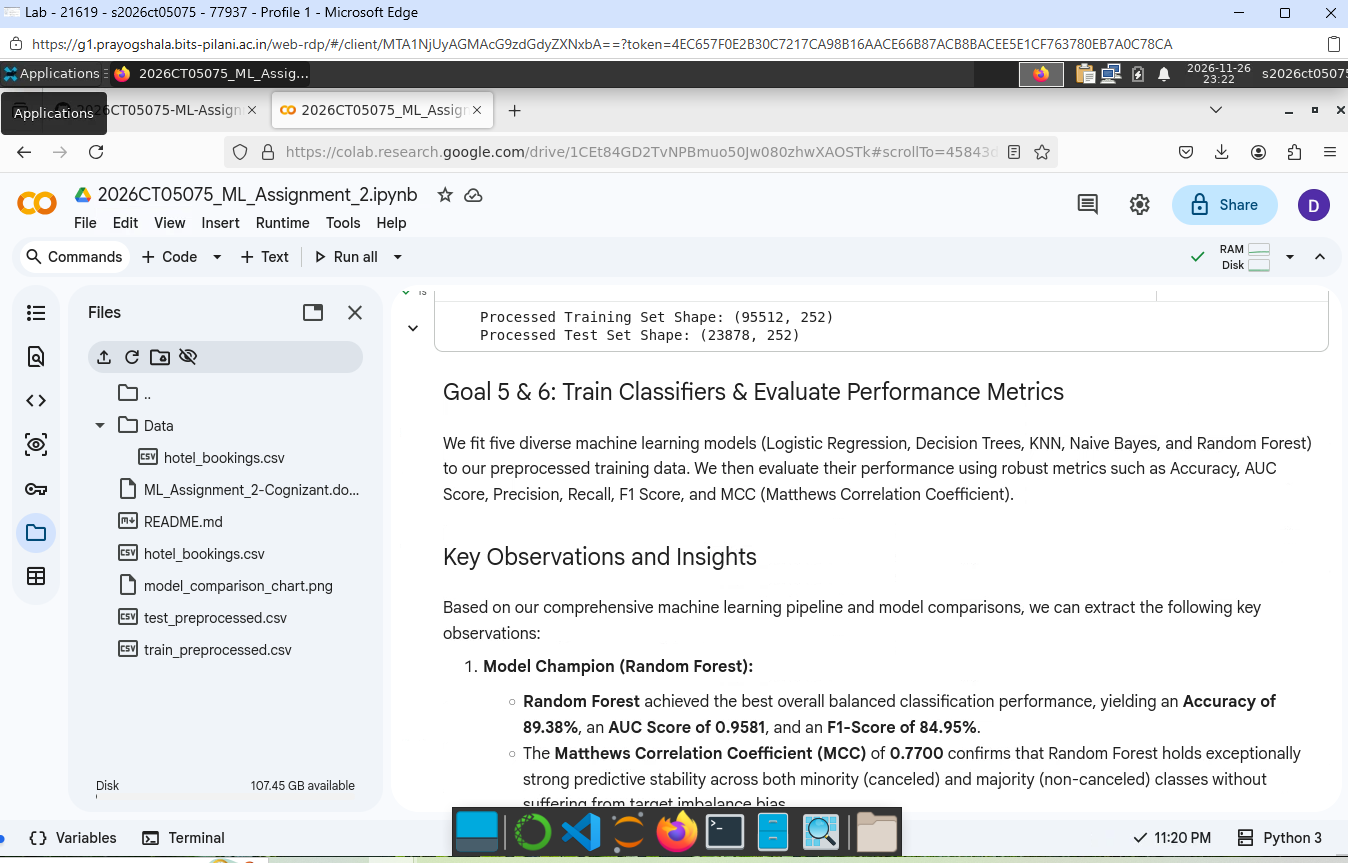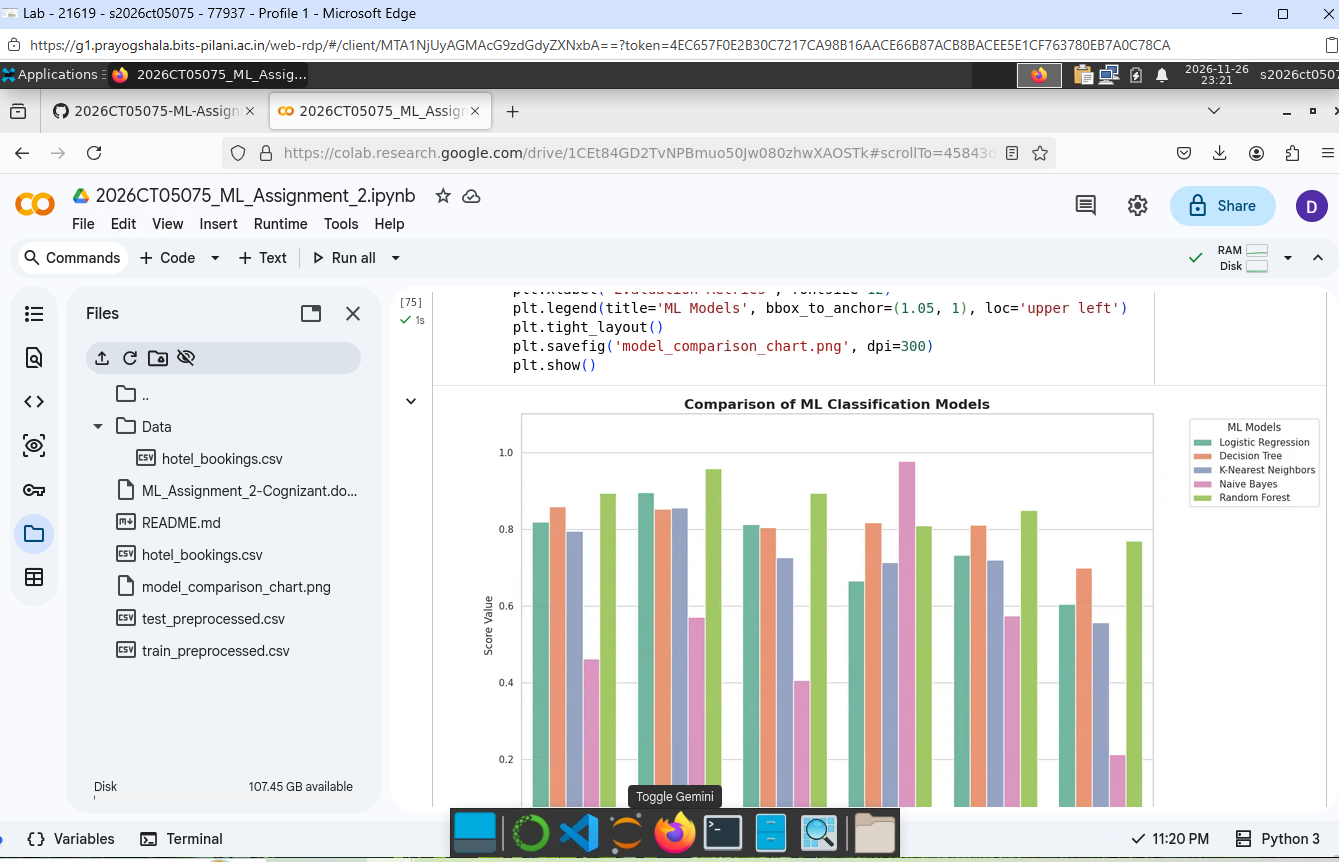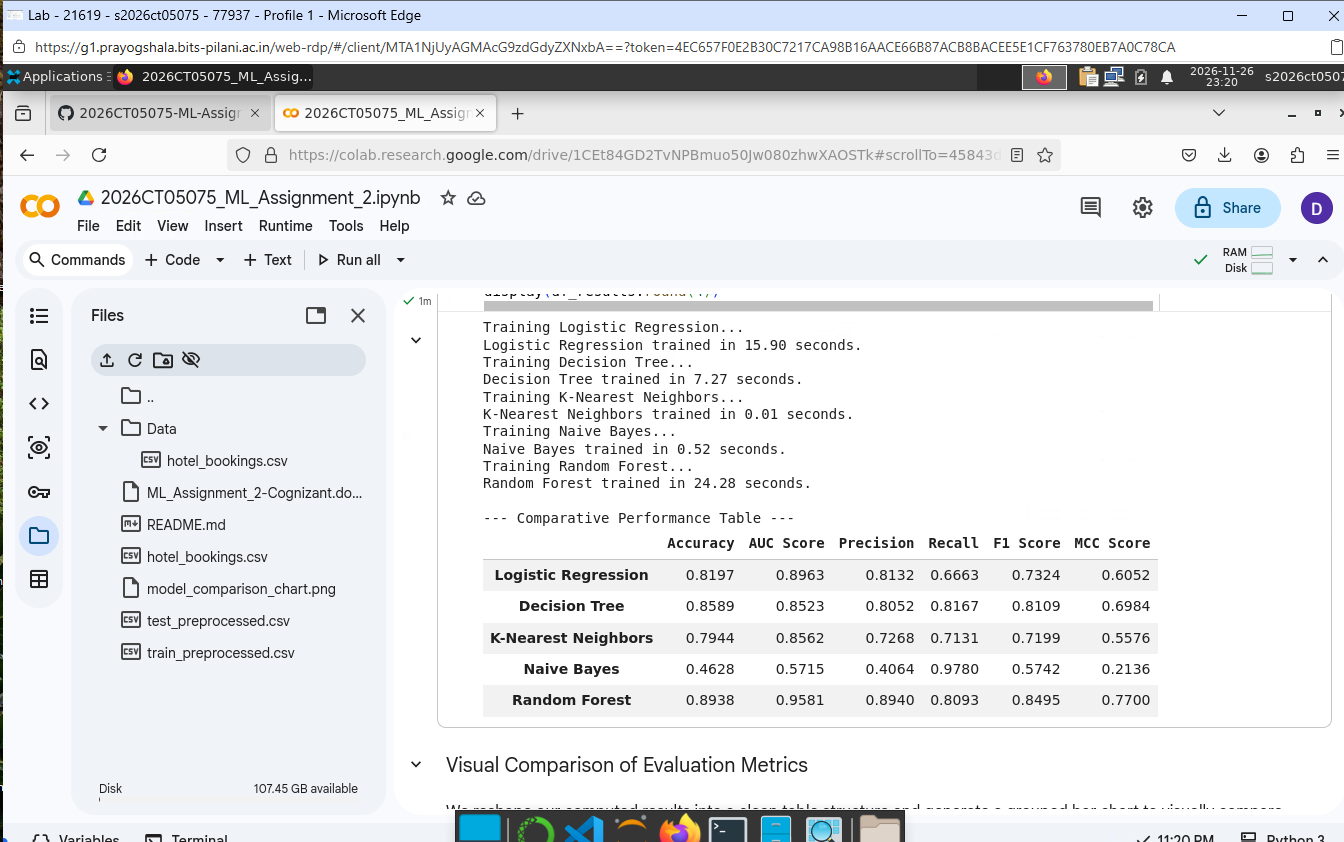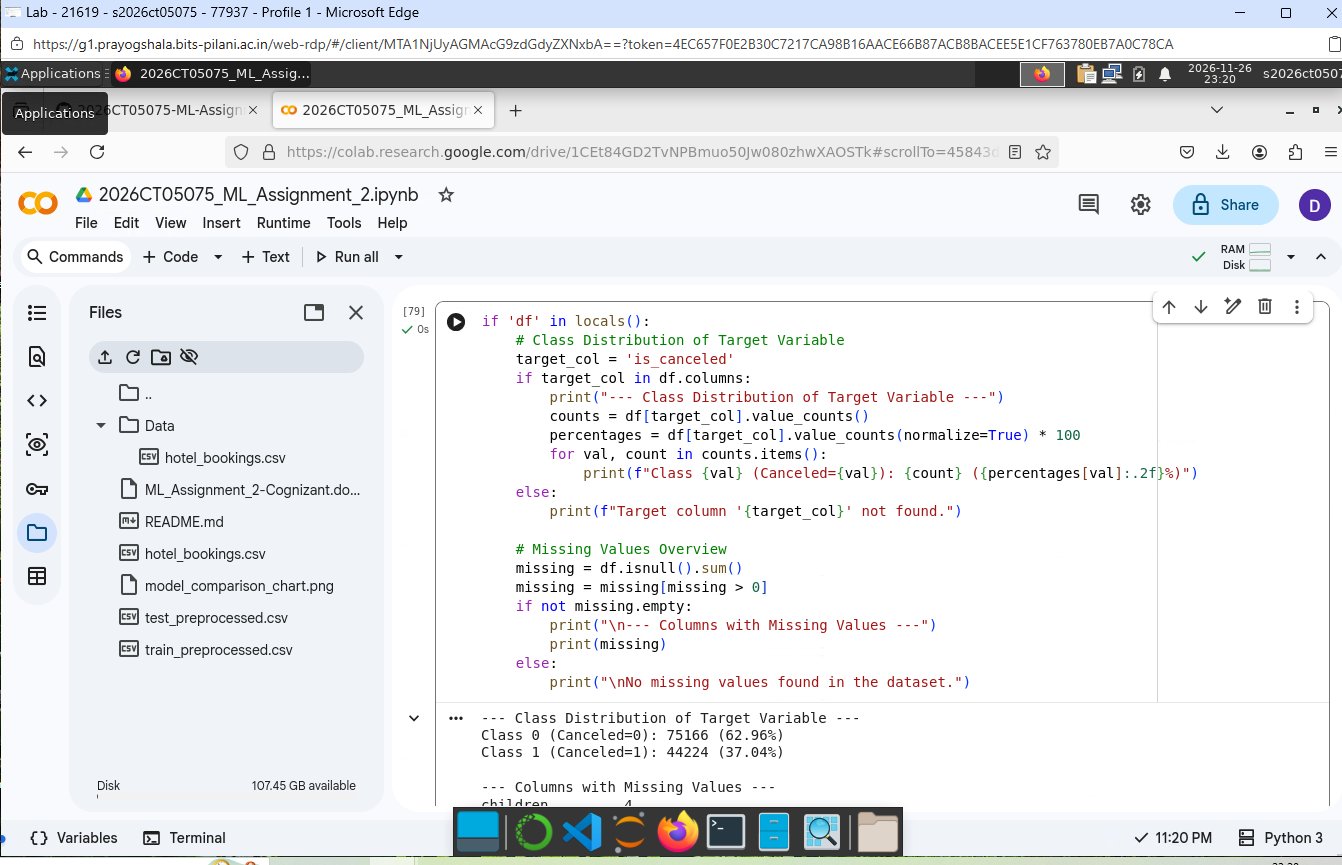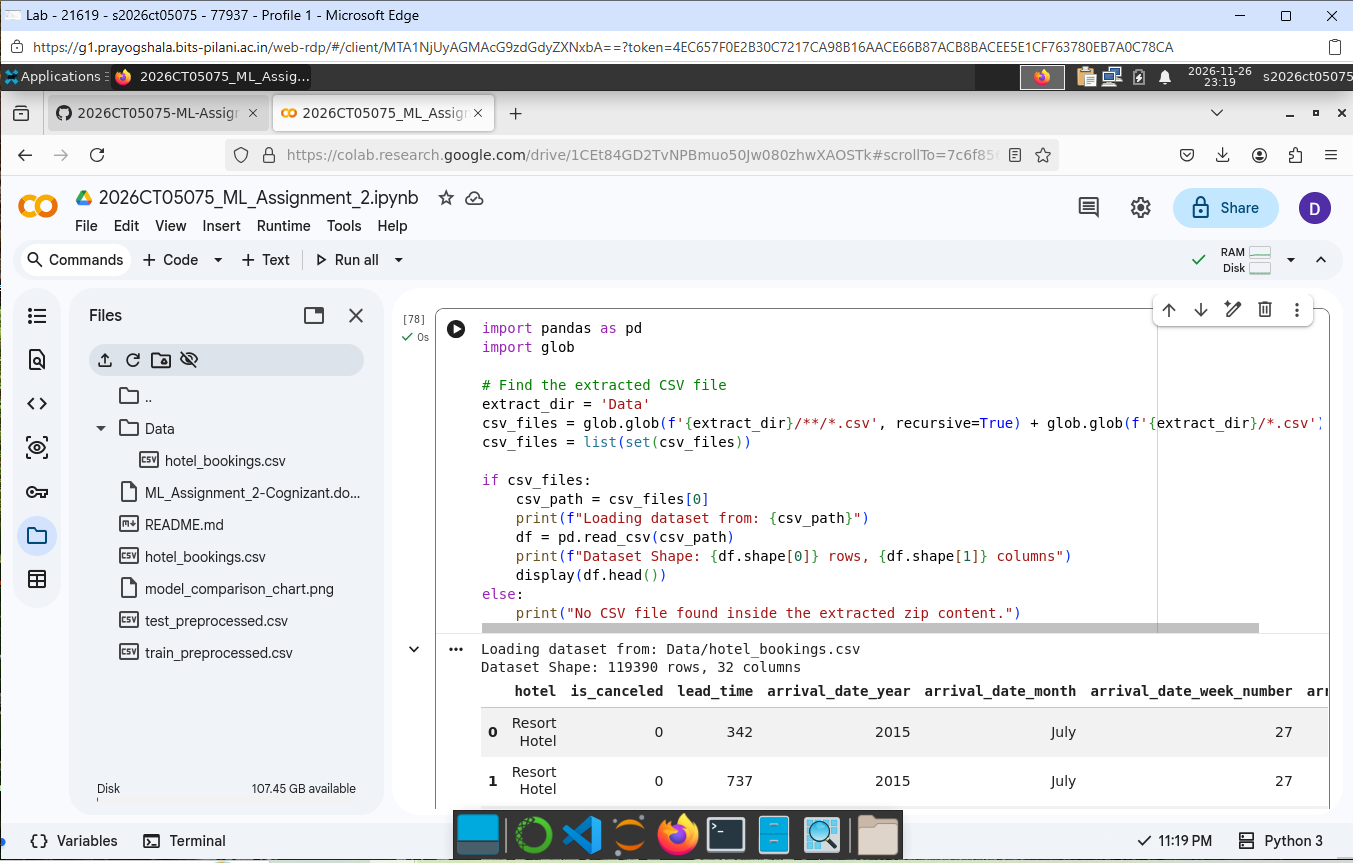